In [44]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
import torch
from torch.utils.data import TensorDataset, DataLoader, Dataset
import torch.nn as nn
from tqdm.notebook import tqdm
from sklearn.preprocessing import StandardScaler
import joblib
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import copy
import seaborn as sns
import random

In [45]:
df0404 = pd.read_csv("../data/labeledAndAnomaly/no_plug/0404.csv")
df0712 = pd.read_csv("../data/labeledAndAnomaly/no_plug/0712.csv")
df1703 = pd.read_csv("../data/labeledAndAnomaly/no_plug/1703.csv")
df2906_1 = pd.read_csv("../data/labeledAndAnomaly/no_plug/2906-1.csv")
df3006_1 = pd.read_csv("../data/labeledAndAnomaly/no_plug/3006-1.csv")
df3006_2 = pd.read_csv("../data/labeledAndAnomaly/no_plug/3006-2.csv")

df1103 = pd.read_csv("../data/labeledAndAnomaly/partial_plug/1103.csv")
df1803 = pd.read_csv("../data/labeledAndAnomaly/partial_plug/1803.csv")
df2503 = pd.read_csv("../data/labeledAndAnomaly/partial_plug/2503.csv")
df2108_1 = pd.read_csv("../data/labeledAndAnomaly/partial_plug/2108-1.csv")


df0612_2 = pd.read_csv("../data/labeledAndAnomaly/plug/0612-2.csv")
df0612_3 = pd.read_csv("../data/labeledAndAnomaly/plug/0612-3.csv")
df0707_1 = pd.read_csv("../data/labeledAndAnomaly/plug/0707-1.csv")
df0707_2 = pd.read_csv("../data/labeledAndAnomaly/plug/0707-2.csv")
df0707_4 = pd.read_csv("../data/labeledAndAnomaly/plug/0707-4.csv")
df0709 = pd.read_csv("../data/labeledAndAnomaly/plug/0709.csv")
df1003 = pd.read_csv("../data/labeledAndAnomaly/plug/1003.csv")
df1112 = pd.read_csv("../data/labeledAndAnomaly/plug/1112.csv")
df1310_2 = pd.read_csv("../data/labeledAndAnomaly/plug/1310-2.csv")
df1310_3 = pd.read_csv("../data/labeledAndAnomaly/plug/1310-3.csv")
df1407_1 = pd.read_csv("../data/labeledAndAnomaly/plug/1407-1.csv")
df1407_2 = pd.read_csv("../data/labeledAndAnomaly/plug/1407-2.csv")
df1407_3 = pd.read_csv("../data/labeledAndAnomaly/plug/1407-3.csv")
df1407_4 = pd.read_csv("../data/labeledAndAnomaly/plug/1407-4.csv")
df1503 = pd.read_csv("../data/labeledAndAnomaly/plug/1503.csv")
df1811 = pd.read_csv("../data/labeledAndAnomaly/plug/1811.csv")
df2106_2 = pd.read_csv("../data/labeledAndAnomaly/plug/2106-2.csv")
df2108_2 = pd.read_csv("../data/labeledAndAnomaly/plug/2108-2.csv")
df2701 = pd.read_csv("../data/labeledAndAnomaly/plug/2701.csv")
df2906_2 = pd.read_csv("../data/labeledAndAnomaly/plug/2906-2.csv")
df2906_3 = pd.read_csv("../data/labeledAndAnomaly/plug/2906-3.csv")
df2906_4 = pd.read_csv("../data/labeledAndAnomaly/plug/2906-4.csv")
df3006_3 = pd.read_csv("../data/labeledAndAnomaly/plug/3006-3.csv")

In [46]:
no_plug_dfs = [df0404, df0712, df1703, df2906_1, df3006_1, df3006_2]
plug_dfs =  [df0612_2, df0612_3, df0707_1, df0707_2, df0707_4, df0709, df1003, df1112, df1310_2, df1310_3,
            df1407_1, df1407_2, df1407_3, df1407_4, df1503, df1811, df2106_2, df2108_2, df2701, 
            df2906_2, df2906_3, df2906_4, df3006_3]
partial_plug_dfs = [df1103, df1803, df2503, df2108_1]

In [47]:
def prepare_phase_stratified_split(
    all_runs,
    feature_cols,
    window_size=60,
    train_ratio=0.60,
    val_ratio=0.20
):
    X_train_list, y_train_list, groups_train = [], [], []
    X_val_list, y_val_list, groups_val = [], [], []
    X_test_list, y_test_list, groups_test = [], [], []

    for run_id, df in enumerate(all_runs):
        # Ensure chronological order
        df_run = (
            df.sort_values('elapsed_runtime_s')
              .reset_index(drop=True)
              .copy()
        )

        # Identify contiguous state blocks
        df_run['state_block'] = (
            df_run['label'] != df_run['label'].shift(1)
        ).cumsum()

        # Process each state block separately
        for block_id, block in df_run.groupby('state_block'):
            block = block.reset_index(drop=True)

            n_samples = len(block)

            train_end = int(n_samples * train_ratio)
            val_end = int(n_samples * (train_ratio + val_ratio))

            # 60% / 20% / 20%
            train_block = block.iloc[:train_end]
            val_block = block.iloc[train_end:val_end]
            test_block = block.iloc[val_end:]

            # -------------------------
            # TRAIN WINDOWS
            # -------------------------
            train_vals = train_block[feature_cols].values
            train_labels = train_block['label'].values

            for i in range(window_size, len(train_vals)):
                X_train_list.append(
                    train_vals[i - window_size:i]
                )
                y_train_list.append(train_labels[i])
                groups_train.append(run_id)

            # -------------------------
            # VALIDATION WINDOWS
            # -------------------------
            val_vals = val_block[feature_cols].values
            val_labels = val_block['label'].values

            for i in range(window_size, len(val_vals)):
                X_val_list.append(
                    val_vals[i - window_size:i]
                )
                y_val_list.append(val_labels[i])
                groups_val.append(run_id)

            # -------------------------
            # TEST WINDOWS
            # -------------------------
            test_vals = test_block[feature_cols].values
            test_labels = test_block['label'].values

            for i in range(window_size, len(test_vals)):
                X_test_list.append(
                    test_vals[i - window_size:i]
                )
                y_test_list.append(test_labels[i])
                groups_test.append(run_id)

    X_train = np.array(X_train_list, dtype=np.float32)
    y_train = np.array(y_train_list, dtype=np.int64)

    X_val = np.array(X_val_list, dtype=np.float32)
    y_val = np.array(y_val_list, dtype=np.int64)

    X_test = np.array(X_test_list, dtype=np.float32)
    y_test = np.array(y_test_list, dtype=np.int64)

    return (
        X_train, y_train,
        X_val, y_val,
        X_test, y_test,
        np.array(groups_train),
        np.array(groups_val),
        np.array(groups_test)
    )

In [48]:
all_runs = no_plug_dfs + plug_dfs + partial_plug_dfs

ORIGINAL_FEATURES = [
    'rel_tot_dp_change',
    'rel_ts_dp_change',
    'rel_p_ts_dp_change',
    'Relative_Ratio_Dev',
    'anomaly_score'
]

X_tr, y_tr, X_val, y_val, X_te, y_te, g_tr, g_val, g_te = (
    prepare_phase_stratified_split(
        all_runs=all_runs,
        feature_cols=ORIGINAL_FEATURES,
    )
)

print(f"Train Shapes: X={X_tr.shape}, y={y_tr.shape}")
print(f"Val Shapes:   X={X_val.shape}, y={y_val.shape}")
print(f"Test Shapes:  X={X_te.shape}, y={y_te.shape}")

Train Shapes: X=(94584, 60, 5), y=(94584,)
Val Shapes:   X=(29010, 60, 5), y=(29010,)
Test Shapes:  X=(29018, 60, 5), y=(29018,)


In [49]:
N_tr, S_tr, F_tr = X_tr.shape

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(
    X_tr.reshape(-1, F_tr)
).reshape(N_tr, S_tr, F_tr)

joblib.dump(scaler, '../models/tst_lstm_scaler.joblib')

['../models/tst_lstm_scaler.joblib']

In [50]:
X_val_scaled = scaler.transform(
    X_val.reshape(-1, F_tr)
).reshape(*X_val.shape)

X_test_scaled = scaler.transform(
    X_te.reshape(-1, F_tr)
).reshape(*X_te.shape)

In [51]:
# --- 4. Dataset & DataLoader ---
class SequenceDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)
        
    def __len__(self):
        return len(self.X)
    
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

In [52]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

In [53]:
set_seed(1908)

train_loader = DataLoader(
    SequenceDataset(X_train_scaled, y_tr),
    batch_size=256,
    shuffle=True
)

val_loader = DataLoader(
    SequenceDataset(X_val_scaled, y_val),
    batch_size=512,
    shuffle=False
)

test_loader = DataLoader(
    SequenceDataset(X_test_scaled, y_te),
    batch_size=512,
    shuffle=False
)

In [54]:
class PlainLSTM(nn.Module):
    def __init__(self, input_dim=4, hidden_dim=32, num_layers=1, num_classes=4, dropout=0.4):
        super().__init__()
        self.lstm = nn.LSTM(input_dim, hidden_dim, num_layers=num_layers, batch_first=True,
                            dropout=dropout if num_layers > 1 else 0.0)
        self.drop = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_dim, num_classes)

    def forward(self, x):
        out, _ = self.lstm(x)
        return self.fc(self.drop(out[:, -1, :]))

In [55]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
mean_t = torch.tensor(scaler.mean_,  dtype=torch.float32, device=device)
std_t  = torch.tensor(scaler.scale_, dtype=torch.float32, device=device)
model = PlainLSTM(input_dim=F_tr, hidden_dim=32, num_layers=1, dropout=0.4).to(device)

In [ ]:
# 1. Calculate class frequencies directly from y_tr
class_counts = np.bincount(y_tr)
total_samples = len(y_tr)

# 2. Compute balanced inverse weights
class_weights = total_samples / (len(class_counts) * class_counts)

# 3. Apply a modest boost to Class 3 to suppress Class 3 -> Class 0/1 leaks
class_weights[3] *= 1.2

# 4. Pass weights to loss function (moves to device automatically with model/data)
weights_tensor = torch.tensor(class_weights, dtype=torch.float32).to(device)
criterion = nn.CrossEntropyLoss(weight=weights_tensor)

In [57]:
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-3)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.5, patience=3
)

In [58]:
def augment_scaled(x_s, mean, std, gain_sigma=0.3, offset_sigma=0.3,
                   noise_sigma=0.1, channel_drop=0.2):
    B, T, F = x_s.shape
    g = torch.exp(torch.randn(B, 1, F, device=x_s.device) * gain_sigma)
    x_s = x_s * g + (g - 1) * (mean / std)                 # gain applied to the raw value
    x_s = x_s + torch.randn(B, 1, F, device=x_s.device) * offset_sigma
    x_s = x_s + torch.randn_like(x_s) * noise_sigma
    if channel_drop > 0:
        keep = (torch.rand(B, 1, F, device=x_s.device) > channel_drop).float()
        x_s = x_s * keep                                    # zero whole channels (= feature set to its mean)
    return x_s

In [59]:
# --- 6. Training Loop ---
EPOCHS = 100
PATIENCE = 10
patience_counter = 0
best_val_loss = float('inf')

print(f"Training Baseline-Subtracted LSTM on {device}...\n")

for epoch in range(1, EPOCHS + 1):
    model.train()
    train_loss, train_correct, train_total = 0.0, 0, 0
    
    for batch_X, batch_y in train_loader:
        batch_X, batch_y = batch_X.to(device), batch_y.to(device)
        batch_X = augment_scaled(batch_X, mean_t, std_t) 
        
        optimizer.zero_grad()
        outputs = model(batch_X)
        loss = criterion(outputs, batch_y)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        
        train_loss += loss.item() * batch_X.size(0)
        preds = torch.argmax(outputs, dim=1)
        train_correct += (preds == batch_y).sum().item()
        train_total += batch_y.size(0)
        
    epoch_train_loss = train_loss / train_total
    epoch_train_acc = (train_correct / train_total) * 100

    # Validation
    model.eval()
    val_loss, val_correct, val_total = 0.0, 0, 0
    with torch.no_grad():
        for batch_X, batch_y in val_loader:
            batch_X, batch_y = batch_X.to(device), batch_y.to(device)
            outputs = model(batch_X)
            loss = criterion(outputs, batch_y)
            
            val_loss += loss.item() * batch_X.size(0)
            preds = torch.argmax(outputs, dim=1)
            val_correct += (preds == batch_y).sum().item()
            val_total += batch_y.size(0)
            
    epoch_val_loss = val_loss / val_total
    epoch_val_acc = (val_correct / val_total) * 100

    scheduler.step(epoch_val_loss)

    # Check validation loss improvement
    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        torch.save(model.state_dict(), '../models/tst_lstm.pth')
        patience_counter = 0  # Reset patience counter on improvement
        saved_msg = "   New Best Val Loss! Weights saved to 'tst_lstm.pth'"
    else:
        patience_counter += 1
        saved_msg = f'   [No Improvement ({patience_counter}/{PATIENCE})]'

    current_lr = optimizer.param_groups[0]['lr']
    print(
      f'Epoch [{epoch:02d}/{EPOCHS:02d}] | LR: {current_lr:.1e} | [TRAIN]'
      f' Loss: {epoch_train_loss:.4f} | Acc: {epoch_train_acc:.2f}% [VALID]'
      f' Loss: {epoch_val_loss:.4f} | Acc: {epoch_val_acc:.2f}%{saved_msg}'
    )

    # Early stopping trigger
    if patience_counter >= PATIENCE:
        print(
            f'\nEarly stopping triggered at Epoch {epoch}'
        )
        break

Training Baseline-Subtracted LSTM on cpu...

Epoch [01/100] | LR: 1.0e-03 | [TRAIN] Loss: 0.9811 | Acc: 59.82% [VALID] Loss: 0.7733 | Acc: 68.46%   New Best Val Loss! Weights saved to 'tst_lstm.pth'
Epoch [02/100] | LR: 1.0e-03 | [TRAIN] Loss: 0.8804 | Acc: 63.79% [VALID] Loss: 0.7686 | Acc: 69.70%   New Best Val Loss! Weights saved to 'tst_lstm.pth'
Epoch [03/100] | LR: 1.0e-03 | [TRAIN] Loss: 0.8667 | Acc: 64.48% [VALID] Loss: 0.7380 | Acc: 69.82%   New Best Val Loss! Weights saved to 'tst_lstm.pth'
Epoch [04/100] | LR: 1.0e-03 | [TRAIN] Loss: 0.8661 | Acc: 64.44% [VALID] Loss: 0.7267 | Acc: 68.39%   New Best Val Loss! Weights saved to 'tst_lstm.pth'
Epoch [05/100] | LR: 1.0e-03 | [TRAIN] Loss: 0.8568 | Acc: 64.77% [VALID] Loss: 0.7424 | Acc: 69.84%   [No Improvement (1/10)]
Epoch [06/100] | LR: 1.0e-03 | [TRAIN] Loss: 0.8525 | Acc: 64.47% [VALID] Loss: 0.7324 | Acc: 70.90%   [No Improvement (2/10)]
Epoch [07/100] | LR: 1.0e-03 | [TRAIN] Loss: 0.8494 | Acc: 64.65% [VALID] Loss: 0.709


================ VALIDATION BENCHMARK ================
Overall Accuracy: 71.86%

              precision    recall  f1-score   support

           0       0.99      0.70      0.82     15435
           1       0.22      0.70      0.33      2735
           2       0.90      0.74      0.81      9517
           3       0.71      0.82      0.76      1323

    accuracy                           0.72     29010
   macro avg       0.70      0.74      0.68     29010
weighted avg       0.87      0.72      0.77     29010



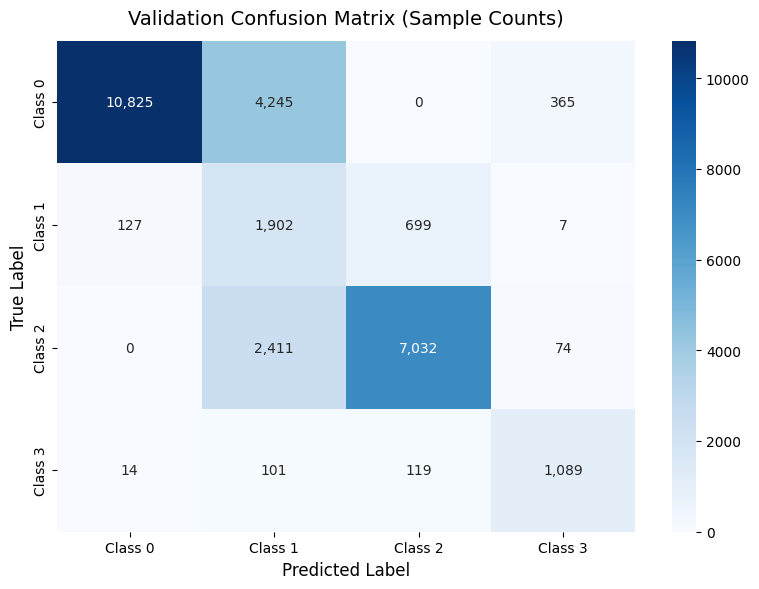

In [60]:
# --- Validation Evaluation & Confusion Matrix ---
model.load_state_dict(
    torch.load('../models/tst_lstm.pth', map_location=device)
)
model.eval()

val_preds, val_targets = [], []

with torch.no_grad():
    for batch_X, batch_y in val_loader:
        batch_X = batch_X.to(device)

        outputs = model(batch_X)
        preds = torch.argmax(outputs, dim=1).cpu().numpy()

        val_preds.extend(preds)
        val_targets.extend(batch_y.numpy())

print("\n================ VALIDATION BENCHMARK ================")
print(
    f"Overall Accuracy: "
    f"{accuracy_score(val_targets, val_preds) * 100:.2f}%\n"
)

print(
    classification_report(
        val_targets,
        val_preds,
        digits=2
    )
)

cm_val = confusion_matrix(val_targets, val_preds)

class_names = [
    'Class 0',
    'Class 1',
    'Class 2',
    'Class 3'
]

fig, ax = plt.subplots(figsize=(8, 6))

sns.heatmap(
    cm_val,
    annot=True,
    fmt=',d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names,
    ax=ax
)

plt.title(
    'Validation Confusion Matrix (Sample Counts)',
    fontsize=14,
    pad=12
)
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)

plt.tight_layout()
plt.show()

In [61]:
# --- 7. Test Evaluation & Confusion Matrix ---
model.load_state_dict(torch.load('../models/tst_lstm.pth', map_location=device))
model.eval()
all_preds, all_targets = [], []
with torch.no_grad():
    for batch_X, batch_y in test_loader:
        batch_X = batch_X.to(device)
        preds = torch.argmax(model(batch_X), dim=1).cpu().numpy()
        all_preds.extend(preds)
        all_targets.extend(batch_y.numpy())

print("\n================ TEST BENCHMARK ================")
print(f"Overall Accuracy: {accuracy_score(all_targets, all_preds) * 100:.2f}%\n")
print(classification_report(all_targets, all_preds, digits=2))


================ TEST BENCHMARK ================
Overall Accuracy: 69.09%

              precision    recall  f1-score   support

           0       0.95      0.67      0.79     15437
           1       0.17      0.51      0.25      2735
           2       0.87      0.77      0.82      9520
           3       0.69      0.75      0.72      1326

    accuracy                           0.69     29018
   macro avg       0.67      0.68      0.64     29018
weighted avg       0.84      0.69      0.74     29018



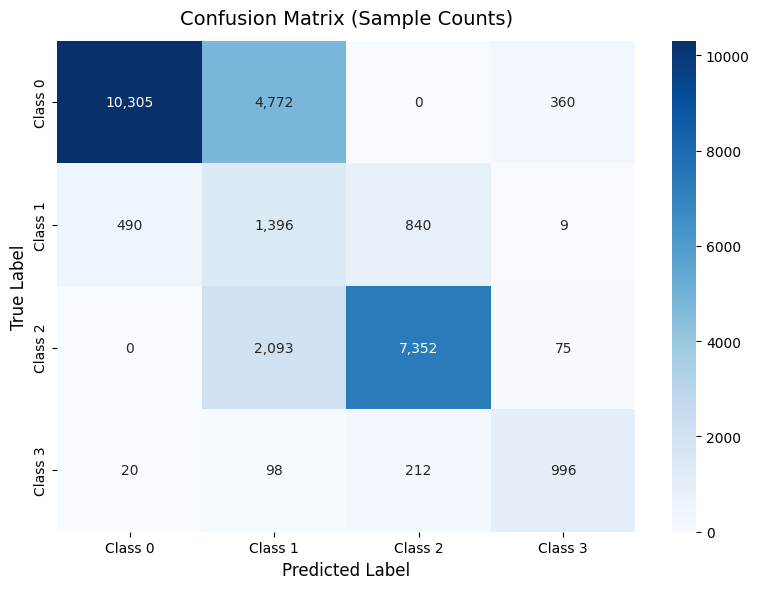

In [62]:
cm = confusion_matrix(all_targets, all_preds)
class_names = ['Class 0', 'Class 1', 'Class 2', 'Class 3']

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt=',d', cmap='Blues', xticklabels=class_names, yticklabels=class_names, ax=ax)
plt.title('Confusion Matrix (Sample Counts)', fontsize=14, pad=12)
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.tight_layout()
plt.show()